# Battery Behavior & Degradation Analysis

## Objective

This notebook analyzes the degradation behavior of Li-ion batteries across discharge cycles.

The analysis focuses on:

- Capacity degradation
- State of Health (SOH)
- Voltage behavior
- Current behavior
- Temperature behavior
- Discharge curve characteristics
- Battery-to-battery variation

The objective is to identify measurable degradation patterns and candidate signals that can be used during feature engineering and machine learning.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Analysis environment ready!")

Analysis environment ready!


In [2]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "battery_discharge_cycles.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (185721, 9)


In [3]:
df.head()
df.info()
df.describe()
df["battery_id"].value_counts()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 185721 entries, 0 to 185720
Data columns (total 9 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   battery_id    185721 non-null  object 
 1   cycle         185721 non-null  int64  
 2   time          185721 non-null  float64
 3   voltage       185721 non-null  float64
 4   current       185721 non-null  float64
 5   temperature   185721 non-null  float64
 6   current_load  185721 non-null  float64
 7   voltage_load  185721 non-null  float64
 8   capacity      185721 non-null  float64
dtypes: float64(7), int64(1), object(1)
memory usage: 12.8+ MB


battery_id
B0005    50285
B0006    50285
B0007    50285
B0018    34866
Name: count, dtype: int64

In [4]:
cycle_df = (
    df.groupby(["battery_id", "cycle"], as_index=False)
      .agg(
          capacity=("capacity", "first"),
          max_temperature=("temperature", "max"),
          min_voltage=("voltage", "min"),
          max_voltage=("voltage", "max"),
          avg_voltage=("voltage", "mean"),
          avg_current=("current", "mean"),
          discharge_duration=("time", "max"),
          samples=("time", "count")
      )
)

cycle_df.head()
print("Cycle-level dataset shape:", cycle_df.shape)

Cycle-level dataset shape: (636, 10)


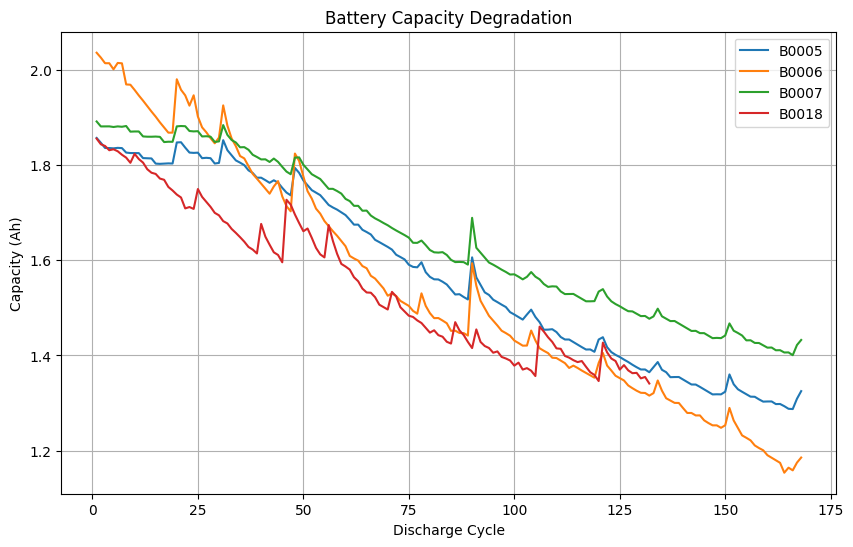

In [5]:
plt.figure(figsize=(10, 6))

for battery_id in cycle_df["battery_id"].unique():
    battery = cycle_df[cycle_df["battery_id"] == battery_id]
    
    plt.plot(
        battery["cycle"],
        battery["capacity"],
        label=battery_id
    )

plt.xlabel("Discharge Cycle")
plt.ylabel("Capacity (Ah)")
plt.title("Battery Capacity Degradation")
plt.legend()
plt.grid(True)
plt.show()

In [6]:
capacity_summary = (
    cycle_df.groupby("battery_id")["capacity"]
    .agg(["first", "last", "min"])
)

capacity_summary["degradation_%"] = (
    (capacity_summary["first"] - capacity_summary["min"])
    / capacity_summary["first"]
    * 100
)

capacity_summary

,first,last,min,degradation_%
battery_id,,,,
B0005,1.856487,1.325079,1.287453,30.651158
B0006,2.035338,1.185675,1.153818,43.310715
B0007,1.891052,1.432455,1.400455,25.943072
B0018,1.855005,1.341051,1.341051,27.706298


In [7]:
cycle_df["initial_capacity"] = (
    cycle_df.groupby("battery_id")["capacity"]
    .transform("first")
)

cycle_df["SOH"] = (
    cycle_df["capacity"]
    / cycle_df["initial_capacity"]
    * 100
)
cycle_df[["battery_id", "cycle", "capacity", "SOH"]].head(10)

,battery_id,cycle,capacity,SOH
0,B0005,1,1.856487,100.000000
1,B0005,2,1.846327,99.452721
2,B0005,3,1.835349,98.861386
3,B0005,4,1.835263,98.856718
4,B0005,5,1.834646,98.823482
5,B0005,6,1.835662,98.878217
6,B0005,7,1.835146,98.850449
7,B0005,8,1.825757,98.344690
8,B0005,9,1.824774,98.291743
9,B0005,10,1.824613,98.283094


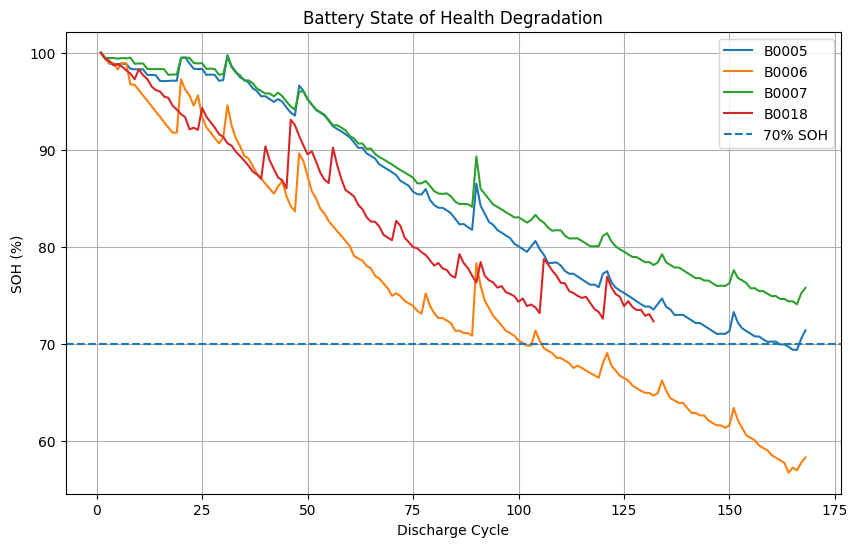

In [8]:
plt.figure(figsize=(10, 6))

for battery_id in cycle_df["battery_id"].unique():
    battery = cycle_df[cycle_df["battery_id"] == battery_id]
    
    plt.plot(
        battery["cycle"],
        battery["SOH"],
        label=battery_id
    )

plt.axhline(70, linestyle="--", label="70% SOH")

plt.xlabel("Discharge Cycle")
plt.ylabel("SOH (%)")
plt.title("Battery State of Health Degradation")
plt.legend()
plt.grid(True)
plt.show()

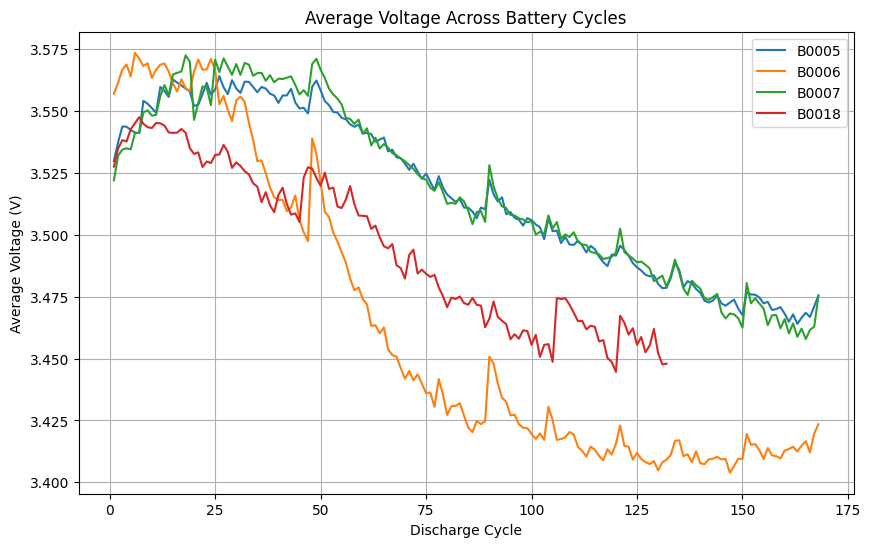

In [9]:
cycle_df.groupby("battery_id")["avg_voltage"].describe()
plt.figure(figsize=(10, 6))

for battery_id in cycle_df["battery_id"].unique():
    battery = cycle_df[cycle_df["battery_id"] == battery_id]
    
    plt.plot(
        battery["cycle"],
        battery["avg_voltage"],
        label=battery_id
    )

plt.xlabel("Discharge Cycle")
plt.ylabel("Average Voltage (V)")
plt.title("Average Voltage Across Battery Cycles")
plt.legend()
plt.grid(True)
plt.show()

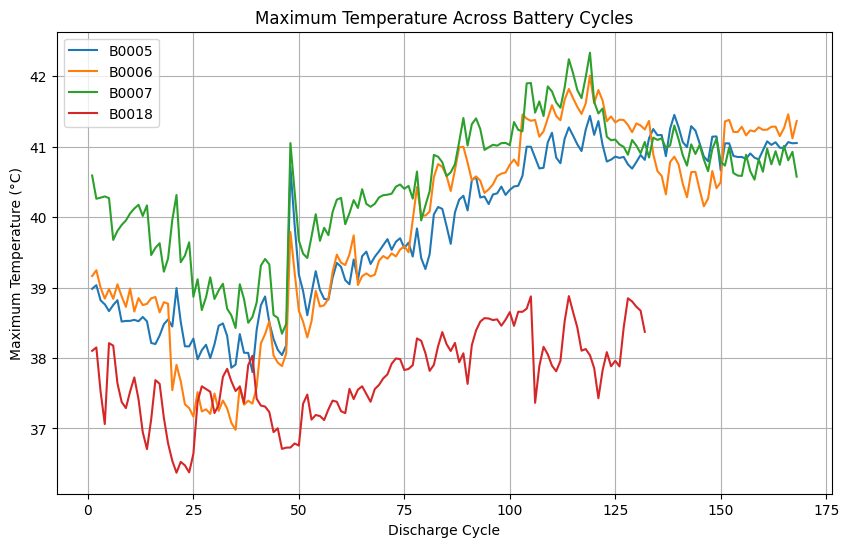

In [10]:
plt.figure(figsize=(10, 6))

for battery_id in cycle_df["battery_id"].unique():
    battery = cycle_df[cycle_df["battery_id"] == battery_id]
    
    plt.plot(
        battery["cycle"],
        battery["max_temperature"],
        label=battery_id
    )

plt.xlabel("Discharge Cycle")
plt.ylabel("Maximum Temperature (°C)")
plt.title("Maximum Temperature Across Battery Cycles")
plt.legend()
plt.grid(True)
plt.show()

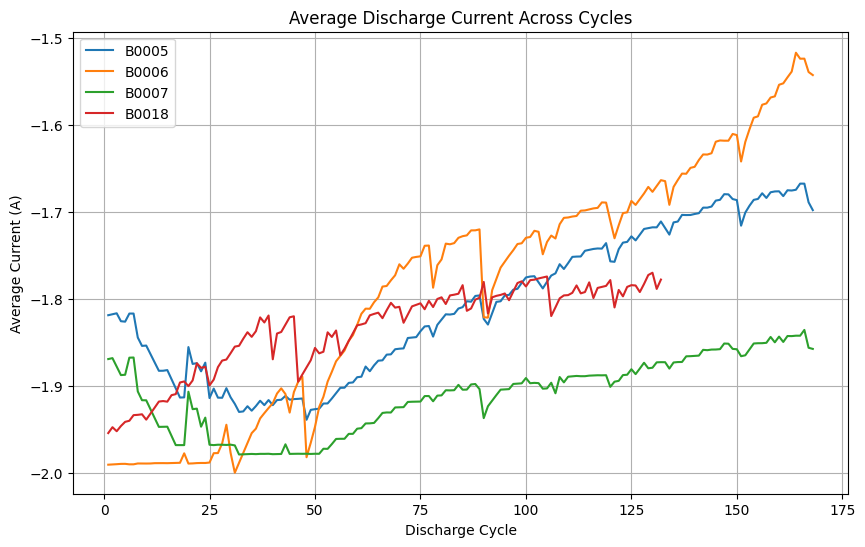

In [11]:
plt.figure(figsize=(10, 6))

for battery_id in cycle_df["battery_id"].unique():
    battery = cycle_df[cycle_df["battery_id"] == battery_id]
    
    plt.plot(
        battery["cycle"],
        battery["avg_current"],
        label=battery_id
    )

plt.xlabel("Discharge Cycle")
plt.ylabel("Average Current (A)")
plt.title("Average Discharge Current Across Cycles")
plt.legend()
plt.grid(True)
plt.show()

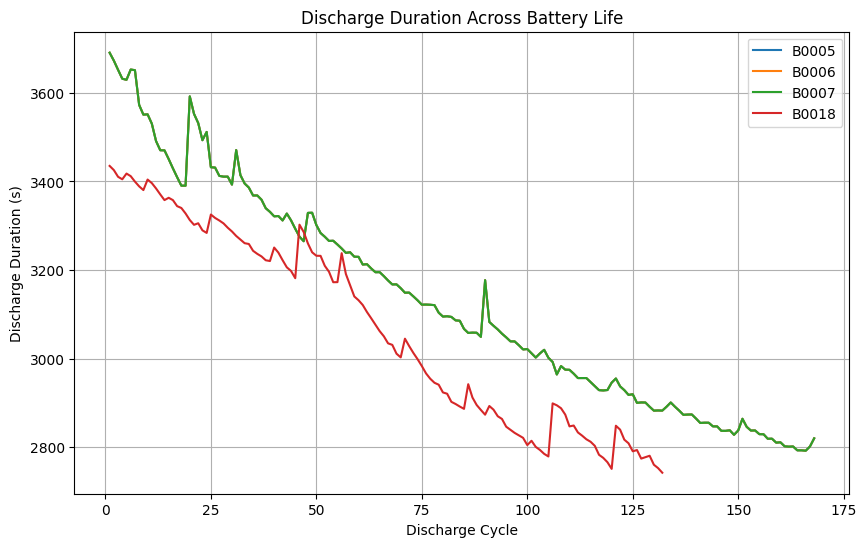

In [12]:
plt.figure(figsize=(10, 6))

for battery_id in cycle_df["battery_id"].unique():
    battery = cycle_df[cycle_df["battery_id"] == battery_id]
    
    plt.plot(
        battery["cycle"],
        battery["discharge_duration"],
        label=battery_id
    )

plt.xlabel("Discharge Cycle")
plt.ylabel("Discharge Duration (s)")
plt.title("Discharge Duration Across Battery Life")
plt.legend()
plt.grid(True)
plt.show()

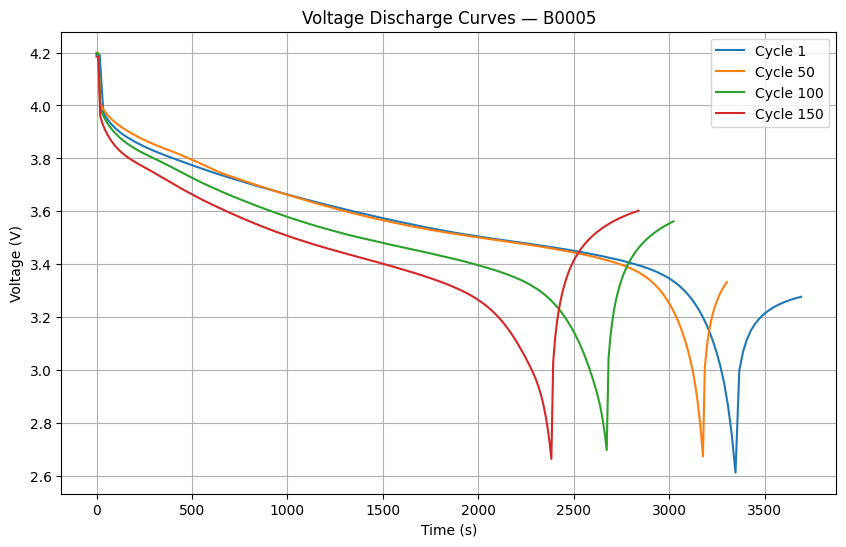

In [13]:
battery_id = "B0005"
cycles_to_plot = [1, 50, 100, 150]
plt.figure(figsize=(10, 6))

for cycle in cycles_to_plot:

    subset = df[
        (df["battery_id"] == battery_id) &
        (df["cycle"] == cycle)
    ]

    plt.plot(
        subset["time"],
        subset["voltage"],
        label=f"Cycle {cycle}"
    )

plt.xlabel("Time (s)")
plt.ylabel("Voltage (V)")
plt.title(f"Voltage Discharge Curves — {battery_id}")
plt.legend()
plt.grid(True)
plt.show()

In [14]:
battery_id = "B0006"

early_cycle = 1
late_cycle = cycle_df[
    cycle_df["battery_id"] == battery_id
]["cycle"].max()

In [15]:
cycle_df.groupby("battery_id").agg(
    initial_capacity=("capacity", "first"),
    final_capacity=("capacity", "last"),
    minimum_capacity=("capacity", "min"),
    initial_soh=("SOH", "first"),
    final_soh=("SOH", "last")
)

,initial_capacity,final_capacity,minimum_capacity,initial_soh,final_soh
battery_id,,,,,
B0005,1.856487,1.325079,1.287453,100.0,71.375616
B0006,2.035338,1.185675,1.153818,100.0,58.254475
B0007,1.891052,1.432455,1.400455,100.0,75.749109
B0018,1.855005,1.341051,1.341051,100.0,72.293702


In [16]:
analysis_columns = [
    "capacity",
    "SOH",
    "max_temperature",
    "min_voltage",
    "max_voltage",
    "avg_voltage",
    "avg_current",
    "discharge_duration",
    "samples"
]

correlation_matrix = cycle_df[analysis_columns].corr()

correlation_matrix

,capacity,SOH,max_temperature,min_voltage,max_voltage,avg_voltage,avg_current,discharge_duration,samples
capacity,1.000000,0.958613,-0.534157,-0.242503,0.153325,0.896274,-0.883573,0.952255,-0.178633
SOH,0.958613,1.000000,-0.559740,-0.200256,0.312725,0.954996,-0.881931,0.888543,-0.188719
max_temperature,-0.534157,-0.559740,1.000000,-0.132822,0.249442,-0.486736,0.445730,-0.509710,0.284798
min_voltage,-0.242503,-0.200256,-0.132822,1.000000,-0.240781,-0.131720,0.451493,-0.113184,0.121816
max_voltage,0.153325,0.312725,0.249442,-0.240781,1.000000,0.398596,-0.363870,0.007987,0.316947
avg_voltage,0.896274,0.954996,-0.486736,-0.131720,0.398596,1.000000,-0.857811,0.796535,-0.154463
avg_current,-0.883573,-0.881931,0.445730,0.451493,-0.363870,-0.857811,1.000000,-0.702162,0.076362
discharge_duration,0.952255,0.888543,-0.509710,-0.113184,0.007987,0.796535,-0.702162,1.000000,-0.209166
samples,-0.178633,-0.188719,0.284798,0.121816,0.316947,-0.154463,0.076362,-0.209166,1.000000


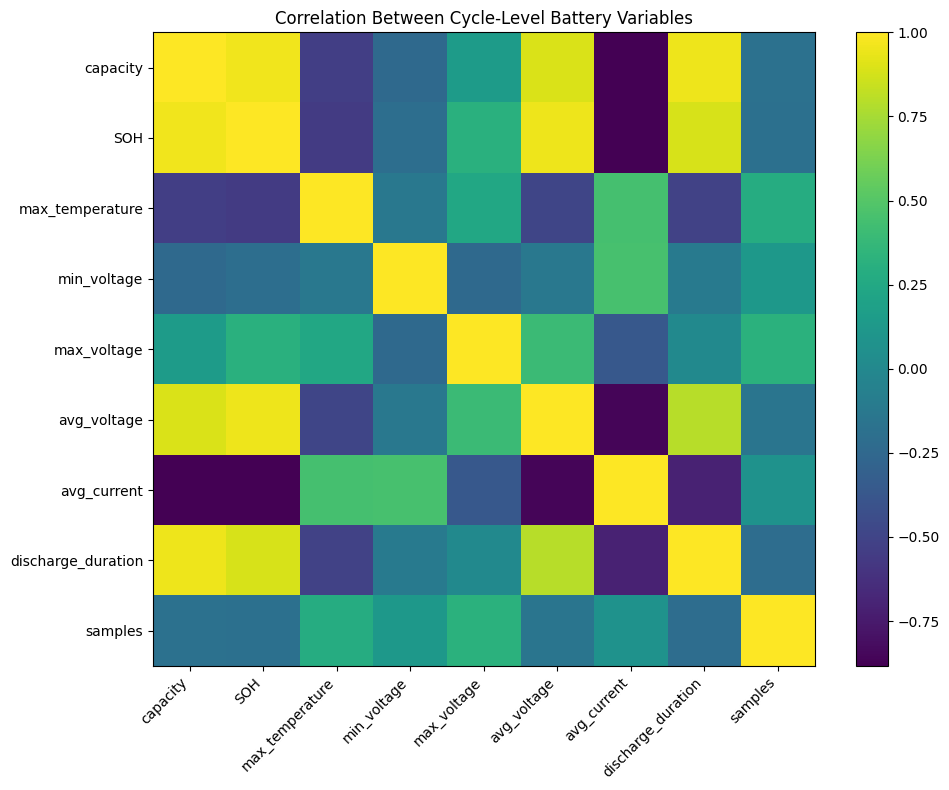

In [17]:
plt.figure(figsize=(10, 8))

plt.imshow(correlation_matrix, aspect="auto")
plt.colorbar()

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns
)

plt.title("Correlation Between Cycle-Level Battery Variables")
plt.tight_layout()
plt.show()

# Key Findings for Feature Engineering

Based on the exploratory analysis:

### Capacity
- Discharge capacity shows an overall decreasing trend with increasing cycle number, indicating progressive battery degradation.
- The rate of degradation differs across batteries, suggesting that battery-specific behavior should be considered during modeling.
- Capacity is strongly related to battery aging and is therefore suitable as the basis for SOH calculation and model evaluation.

### SOH
- SOH decreases as the discharge cycle count increases for all four batteries.
- The degradation profiles are not identical, indicating variation in aging behavior between batteries.
- SOH will be used as an important target variable for subsequent machine learning analysis.

### Voltage
- Discharge voltage decreases during each discharge operation.
- Voltage-related characteristics change across the battery lifetime and may contain information about degradation.
- Voltage curve shape and voltage-derived statistics should therefore be investigated during feature engineering.

### Temperature
- Battery temperature increases during discharge operations.
- Maximum temperature and temperature variation may provide useful indicators of battery operating condition and degradation.
- Temperature-based statistical and curve-derived features should be investigated.

### Current
- Discharge current remains relatively consistent because of the controlled experimental discharge conditions.
- Therefore, simple average current may have limited predictive value, while current variability and current-related curve characteristics may still be worth evaluating.

### Discharge behavior
- Discharge operations contain variable-length time-series measurements.
- Discharge duration and the shape of voltage, current, and temperature curves vary across cycles.
- Curve-based characteristics and statistical summaries may provide useful fixed-length representations for machine learning.

### Battery-to-battery variation
- The four batteries show different initial capacities and different degradation patterns.
- B0006 shows comparatively greater capacity degradation, while B0007 retains a larger proportion of its initial capacity.
- This variation highlights the importance of evaluating ML models across multiple batteries rather than relying on a single battery.

### Recommended features for further investigation
- Initial, minimum, maximum and average voltage
- Voltage drop and voltage range
- Voltage curve slope and area under the discharge curve
- Initial, maximum and average temperature
- Temperature rise and temperature variation
- Average and standard deviation of current
- Discharge duration
- Voltage-current relationship
- Voltage-temperature relationship
- Curve-based features derived from discharge profiles
- Cycle number as an aging-related feature

In [18]:
print(type(cycle_df))
print("Shape:", cycle_df.shape)

<class 'pandas.core.frame.DataFrame'>
Shape: (636, 12)


In [19]:
cycle_df.head()

,battery_id,cycle,capacity,max_temperature,min_voltage,max_voltage,avg_voltage,avg_current,discharge_duration,samples,initial_capacity,SOH
0,B0005,1,1.856487,38.982181,2.612467,4.191492,3.529829,-1.818702,3690.234,197,1.856487,100.000000
1,B0005,2,1.846327,39.033398,2.587209,4.189773,3.537320,-1.817560,3672.344,196,1.856487,99.452721
2,B0005,3,1.835349,38.818797,2.651917,4.188187,3.543737,-1.816487,3651.641,195,1.856487,98.861386
3,B0005,4,1.835263,38.762305,2.592948,4.188461,3.543666,-1.825589,3631.563,194,1.856487,98.856718
4,B0005,5,1.834646,38.665393,2.547420,4.188299,3.542343,-1.826114,3629.172,194,1.856487,98.823482
